# ENZERA - 05 Deep learning baseline: 1D-CNN on the raw daily series

**Question.** Our XGBoost uses 17 handcrafted features. Can a 1D convolutional neural network that reads the **raw
1,034-day series** directly do better? This is the main "future work" item, inspired by Zheng et al. (2018), who used a
Wide & Deep CNN on SGCC.

**Protocol.** Same split as `ml/train.py`: fit on `tr_fit` (25,211), early stopping and threshold on validation (4,449),
report on test (6,356). Same `evaluate()` function. The comparison is the **deployed** XGBoost model.

**Input per customer** (2 channels × 1,034 days): `log(1 + kWh)` after the same gap-aware cleaning as the features (gaps
between readings interpolated, no filling outside the observed span, missing → 0), and a 0/1 *observed* mask, so the network
knows which zeros are missing data.

**Network.** 3 × [Conv1d → BatchNorm → ReLU → MaxPool(2)] with 16/32/64 filters (kernel sizes 7, 7, 5), then global
average + max pooling, a 32-unit dense layer with dropout 0.3, and one output logit. Loss: binary cross-entropy with
`pos_weight` = #normal/#theft (the same class weighting as XGBoost). Adam, learning rate 1e-3, batch size 256, at most
15 epochs, early stopping on validation PR-AUC (patience 3).

**Decision rule (fixed before running).** A CNN-based model replaces the deployed XGBoost only if it improves test PR-AUC
**and** top-10% recall by ≥ 0.01 without being worse on validation, **and** it can run on the free 512 MB Render instance.

In [1]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch import nn
from sklearn.model_selection import train_test_split
from sklearn.metrics import average_precision_score
from scipy.stats import rankdata

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from ml.features import clean_inside, compute_features, split_wide
from ml.scoring import load_bundle
from ml.train import SEED, best_f1_threshold, evaluate
import matplotlib.pyplot as plt
%matplotlib inline

torch.manual_seed(SEED); np.random.seed(SEED); torch.set_num_threads(4)
ids, labels, dates, values = split_wide(pd.read_csv(ROOT / "data/raw/data.csv"))
y = labels
idx = np.arange(len(ids))
tr, rest = train_test_split(idx, test_size=0.30, stratify=labels, random_state=SEED)
te, demo = train_test_split(rest, test_size=0.50, stratify=labels[rest], random_state=SEED)
tr_fit, val = train_test_split(tr, test_size=0.15, stratify=labels[tr], random_state=SEED)

# deployed XGBoost scores for the comparison (computed first, then the raw data is freed to save memory)
bundle = load_bundle(ROOT / "models/enzera_model.joblib")
xgb_score = lambda rows: bundle["model"].predict_proba(compute_features(values[rows], dates).to_numpy())[:, 1]
xgb_val, xgb_te = xgb_score(val), xgb_score(te)

def make_input(rows):
    x = clean_inside(values[rows])
    obs = ~np.isnan(x)
    return np.stack([np.log1p(np.nan_to_num(x, nan=0.0)), obs], axis=1).astype(np.float16)

Xtr, Xval, Xte = make_input(tr_fit), make_input(val), make_input(te)
ytr, yval, yte = y[tr_fit], y[val], y[te]
del values
print("input shapes:", Xtr.shape, Xval.shape, Xte.shape, "| bundle", bundle["version"])

input shapes: (25211, 2, 1034) (4449, 2, 1034) (6356, 2, 1034) | bundle xgb-20261114-1521


In [2]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        def block(cin, cout, k):
            return nn.Sequential(nn.Conv1d(cin, cout, k, padding=k // 2), nn.BatchNorm1d(cout), nn.ReLU(), nn.MaxPool1d(2))
        self.conv = nn.Sequential(block(2, 16, 7), block(16, 32, 7), block(32, 64, 5))
        self.head = nn.Sequential(nn.Linear(128, 32), nn.ReLU(), nn.Dropout(0.3), nn.Linear(32, 1))

    def forward(self, x):
        h = self.conv(x)
        return self.head(torch.cat([h.mean(dim=2), h.amax(dim=2)], dim=1)).squeeze(1)


def predict(model, X, bs=1024):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            out.append(torch.sigmoid(model(torch.from_numpy(X[i:i + bs].astype(np.float32)))).numpy())
    return np.concatenate(out)


model = CNN()
print(f"parameters: {sum(p.numel() for p in model.parameters()):,}")
pos_weight = torch.tensor((ytr == 0).sum() / (ytr == 1).sum(), dtype=torch.float32)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
rng = np.random.default_rng(SEED)

history, best, best_state, wait = [], -1, None, 0
for epoch in range(1, 16):
    t0 = time.time(); model.train(); order = rng.permutation(len(Xtr)); total = 0.0
    for i in range(0, len(order), 256):
        b = order[i:i + 256]
        xb = torch.from_numpy(Xtr[b].astype(np.float32)); yb = torch.from_numpy(ytr[b].astype(np.float32))
        opt.zero_grad(); loss = loss_fn(model(xb), yb); loss.backward(); opt.step()
        total += loss.item() * len(b)
    val_ap = average_precision_score(yval, predict(model, Xval))
    history.append({"epoch": epoch, "train_loss": total / len(Xtr), "val_pr_auc": val_ap})
    print(f"epoch {epoch:2d}  loss {total / len(Xtr):.4f}  val PR-AUC {val_ap:.4f}  ({time.time() - t0:.0f}s)")
    if val_ap > best:
        best, wait = val_ap, 0
        best_state = {k: v.clone() for k, v in model.state_dict().items()}
    else:
        wait += 1
        if wait >= 3:
            print("early stopping"); break
model.load_state_dict(best_state)
print(f"best validation PR-AUC {best:.4f}")

parameters: 18,545


epoch  1  loss 1.1434  val PR-AUC 0.2420  (52s)


epoch  2  loss 1.0876  val PR-AUC 0.2657  (53s)


epoch  3  loss 1.0491  val PR-AUC 0.3011  (58s)


epoch  4  loss 1.0377  val PR-AUC 0.3035  (61s)


epoch  5  loss 1.0061  val PR-AUC 0.3151  (43s)


... (6 outputs left out)

epoch 12  loss 0.8930  val PR-AUC 0.3462  (42s)


epoch 13  loss 0.8656  val PR-AUC 0.3378  (47s)


epoch 14  loss 0.8623  val PR-AUC 0.3265  (67s)


epoch 15  loss 0.8610  val PR-AUC 0.3172  (53s)
early stopping
best validation PR-AUC 0.3462


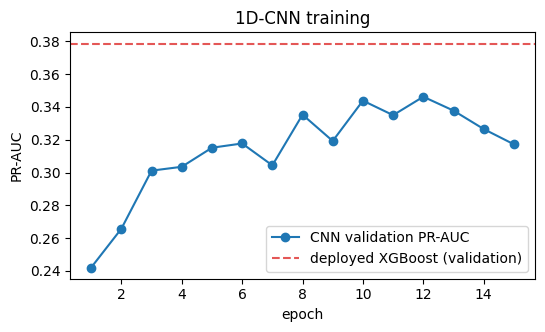

In [3]:
h = pd.DataFrame(history)
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(h.epoch, h.val_pr_auc, "o-", label="CNN validation PR-AUC")
ax.axhline(average_precision_score(yval, xgb_val), color="#E45756", ls="--", label="deployed XGBoost (validation)")
ax.set_xlabel("epoch"); ax.set_ylabel("PR-AUC"); ax.legend(); ax.set_title("1D-CNN training")
plt.show()

## Comparison on the test split

In [4]:
cnn_val, cnn_te = predict(model, Xval), predict(model, Xte)

def rank_avg(a, b):  # simple ensemble: average of the two models' percentile ranks
    return (rankdata(a) + rankdata(b)) / (2 * len(a))

cands = {
    "XGBoost, 17 features (deployed)": (xgb_val, xgb_te),
    "1D-CNN, raw daily series": (cnn_val, cnn_te),
    "Ensemble: XGBoost + CNN (rank average)": (rank_avg(xgb_val, cnn_val), rank_avg(xgb_te, cnn_te)),
}
rows = []
for name, (pv, pt) in cands.items():
    r = evaluate(yte, pt, best_f1_threshold(yval, pv)); r["val_pr_auc"] = average_precision_score(yval, pv)
    rows.append({"model": name, **r})
res = pd.DataFrame(rows).set_index("model")
table = res[["precision", "recall", "f1", "roc_auc", "pr_auc", "recall_at_top10", "val_pr_auc"]].round(3)
table.columns = ["Precision", "Recall", "F1", "ROC-AUC", "PR-AUC", "Theft caught in top 10%", "PR-AUC (validation)"]
table.to_csv(ROOT / "reports/cnn_comparison.csv")
table

,Precision,Recall,F1,ROC-AUC,PR-AUC,Theft caught in top 10%,PR-AUC (validation)
model,,,,,,,
"XGBoost, 17 features (deployed)",0.394,0.394,0.394,0.798,0.376,0.435,0.379
"1D-CNN, raw daily series",0.342,0.512,0.410,0.811,0.391,0.459,0.346
Ensemble: XGBoost + CNN (rank average),0.414,0.440,0.427,0.831,0.433,0.466,0.404


In [5]:
base = res.iloc[0]
dec = pd.DataFrame({"d PR-AUC (test)": res["pr_auc"] - base["pr_auc"],
                    "d top10 (test)": res["recall_at_top10"] - base["recall_at_top10"],
                    "d PR-AUC (val)": res["val_pr_auc"] - base["val_pr_auc"]}).iloc[1:]
dec["passes metric rule?"] = (dec["d PR-AUC (test)"] >= 0.01) & (dec["d top10 (test)"] >= 0.01) & (dec["d PR-AUC (val)"] >= 0)
print(dec.round(4).to_string())

rng_b = np.random.default_rng(SEED); diffs = []
best_name = res.iloc[1:]["pr_auc"].idxmax(); best_p = cands[best_name][1]
for _ in range(1000):
    b = rng_b.integers(0, len(yte), len(yte))
    diffs.append(average_precision_score(yte[b], best_p[b]) - average_precision_score(yte[b], xgb_te[b]))
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"\nBest CNN-based model: {best_name}; PR-AUC vs deployed {res.loc[best_name, 'pr_auc'] - base['pr_auc']:+.4f}, 95% CI [{lo:+.4f}, {hi:+.4f}]")
print("Correlation (Spearman) of CNN and XGBoost test scores:", round(pd.Series(cnn_te).corr(pd.Series(xgb_te), method="spearman"), 3))

                                        d PR-AUC (test)  d top10 (test)  d PR-AUC (val)  passes metric rule?
model                                                                                                       
1D-CNN, raw daily series                         0.0152          0.0239         -0.0325                False
Ensemble: XGBoost + CNN (rank average)           0.0578          0.0313          0.0253                 True



Best CNN-based model: Ensemble: XGBoost + CNN (rank average); PR-AUC vs deployed +0.0578, 95% CI [+0.0339, +0.0796]
Correlation (Spearman) of CNN and XGBoost test scores: 0.541


## Conclusion

**Result.** The 1D-CNN on the raw daily series learns real theft signal (test PR-AUC 0.391, ROC-AUC 0.811), but on its own
it is **not reliably better** than the deployed XGBoost. It is ahead on test but behind on validation (0.346 vs 0.379),
so it fails the decision rule. Its training was also noisy: validation PR-AUC jumped between 0.30 and 0.35 from epoch to
epoch, with the best at epoch 12.

**The ensemble is clearly better.** Averaging the percentile ranks of the two models gives test PR-AUC **0.433** (+0.058 vs
the deployed model, paired bootstrap 95% CI [+0.034, +0.080]), ROC-AUC 0.831, top-10% recall **46.6%** (vs 43.5%), and it is
also better on validation (0.404 vs 0.379). It passes the metric rule. The two models agree only moderately (Spearman 0.541):
the CNN sees day-level shapes that 17 summary features cannot capture, and XGBoost sees robust summary statistics.

**Deployment decision.** The ensemble is *not* deployed in this version, for two reasons:
1. **Explainability.** ENZERA's reasons, waterfall and what-if use exact TreeSHAP values, which exist only for the tree model.
   With the ensemble, half of every score would come from a network whose explanations would need approximate,
   gradient-based methods.
2. **Hosting cost.** PyTorch does not fit the free 512 MB Render instance next to the API. A deployment would require
   exporting the CNN to ONNX and running it with `onnxruntime`.

Both are solvable. The ensemble is the strongest model we built and the clearest direction for future work.